In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
figsave='figures_draft'

### GSEA heatmap

In [3]:
import gseapy as gp

In [4]:
import pickle 
with open('../DEGs/pyDESeq2/DESeq2_iNeurons_results_v3_all.pkl','rb') as f:
    iN_DEGs = pickle.load(f)

In [5]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index
common_genes = set(iA_top_genes) & set (iN_top_genes)
common_genes

{'CCT3',
 'CHMP7',
 'DCAF7',
 'FDFT1',
 'HDAC2',
 'LSM4',
 'MRPL39',
 'RPA3',
 'RPL10',
 'RPL30',
 'SOD1',
 'SOD2',
 'SYVN1',
 'UBA1',
 'WDR12'}

In [6]:
import pickle
with open("/lustre/scratch126/cellgen/lotfollahi/so21/patientAtlases/Gabitto2024NatureMed/SuppTable6.pkl", "rb") as f:
    genesets = pickle.load(f)

In [7]:
hallmarks = pd.read_csv('/nfs/team361/so21/genesets/h.all.v2026.1.Hs.symbols.gmt.txt', sep='\t', header=None)
hallmark_dict = (
    hallmarks
    .set_index(0)          # hallmark name as index
    .iloc[:, 1:]           # drop the URL column
    .apply(lambda row: row.dropna().tolist(), axis=1)
    .to_dict()
)

In [8]:
def run_gsea_for_common(de_dict, cell_type, selected_perturbations, genesets):
    out = []

    for pert in selected_perturbations:
        if pert not in de_dict:
            continue

        de = de_dict[pert]

        rnk = (
            de[["variable", "stat"]]
            .rename(columns={"variable": "gene", "stat": "score"})
            .dropna()
            .drop_duplicates("gene")
            .sort_values("score", ascending=False)
        )

        pre = gp.prerank(
            rnk=rnk,
            gene_sets=genesets,
            permutation_num=1000,
            min_size=5,
            max_size=500,
            outdir=None,
            seed=6,
            verbose=False,
        )

        tmp = pre.res2d.copy()
        tmp["perturbation"] = pert
        tmp["cell_type"] = cell_type
        out.append(tmp)

    return pd.concat(out, ignore_index=True)

### combined

In [9]:
iN_gsea = run_gsea_for_common(de_dict = iN_DEGs, 
                              cell_type="iNeurons", 
                              selected_perturbations=list(iN_nDEGs_df.index),
                              genesets=genesets|hallmark_dict)

2026-08-14 15:42:01,167 [WARNING] Duplicated values found in preranked stats: 1.18% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-08-14 15:42:16,537 [WARNING] Duplicated values found in preranked stats: 1.35% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-08-14 15:42:31,133 [WARNING] Duplicated values found in preranked stats: 1.54% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-08-14 15:42:45,788 [WARNING] Duplicated values found in preranked stats: 1.67% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-08-14 15:42:59,676 [WARNING] Duplicated values found in preranked stats: 2.63% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-08-14 15:43:13,216 [WARNING] Duplicated values found in preranked stats: 1.23% of genes
The order of those genes will be

In [10]:
iN_gsea.to_csv('temp_iN_gsea2_v2.csv')

In [9]:
iN_gsea = pd.read_csv('temp_iN_gsea2_v2.csv', index_col=0)
iN_gsea

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,perturbation,cell_type
0,prerank,Ribosomal proteins,-0.586785,-1.967239,0.000000,0.001008,0.001,59/86,26.41%,RPL10A;RPL36;RPL34;RPS14;RPS20;RPS4X;RPL39L;RP...,AARD,iNeurons
1,prerank,HALLMARK_OXIDATIVE_PHOSPHORYLATION,-0.506950,-1.890228,0.000000,0.003025,0.006,102/200,19.75%,ECHS1;UQCR10;ACO2;ABCB7;FH;NDUFB2;CYCS;SDHC;ND...,AARD,iNeurons
2,prerank,Transcription factors-zf-GATA,0.735392,1.606690,0.009042,0.346080,0.302,5/14,12.21%,GATAD2B;GATAD2A;TRPS1;MTA1;RERE,AARD,iNeurons
3,prerank,Electron transport chain components,-0.460553,-1.546440,0.002525,0.250753,0.533,42/92,19.75%,NDUFB2;NDUFA13;NDUFS4;COX7A2;NDUFB1;COX7C;COX4...,AARD,iNeurons
4,prerank,HALLMARK_UV_RESPONSE_UP,-0.410069,-1.474373,0.000000,0.368567,0.768,58/156,17.28%,WIZ;POLE3;MAOA;SQSTM1;HYAL2;RFC4;APOM;FGF18;KL...,AARD,iNeurons
...,...,...,...,...,...,...,...,...,...,...,...,...
34855,prerank,Transcription factors-CSD,-0.344865,-0.679497,0.886831,0.972937,1.000,3/8,15.19%,CARHSP1;YBX3;LIN28A,ZYX,iNeurons
34856,prerank,Transcription factors-zf-BED,-0.354692,-0.643017,0.898551,0.971351,1.000,3/6,20.51%,ZBED1;ZBED5;ZBED3,ZYX,iNeurons
34857,prerank,Microglia plaque induced genes,0.244539,0.582752,0.984877,1.000000,1.000,1/19,8.50%,HEXB,ZYX,iNeurons
34858,prerank,Fc receptors and MHCII,0.218730,0.534757,0.992674,1.000000,1.000,1/21,3.95%,HLA-DOA,ZYX,iNeurons


In [10]:
len(iN_gsea.perturbation.unique())

249

In [11]:
sns.set_style('ticks')

In [12]:
# signatures significant in at least x perturbation

min_perts = 3

sig_terms = (
    iN_gsea.loc[iN_gsea["FDR q-val"] < 0.05]
    .groupby("Term")["perturbation"]
    .nunique()
)

sig_terms = sig_terms[sig_terms >= min_perts].index

# keep only those signatures
plot_df = iN_gsea[iN_gsea["Term"].isin(sig_terms)]

# NES matrix
heatmap_df = plot_df.pivot(
    index="Term",
    columns="perturbation",
    values="NES"
)

### GSVA heatmap with significant terms

In [13]:
keep_terms = list(sig_terms)
signatures = genesets|hallmark_dict
signatures = {k:v for k,v in signatures.items() if k in keep_terms}

In [14]:
def get_ot_scores(disease_id):
    query = """
    query DiseaseAssociations($efoId: String!) {
      disease(efoId: $efoId) {
        associatedTargets(page: {index: 0, size: 1000}) {
          rows {
            target {
              approvedSymbol
            }
            score
          }
        }
      }
    }
    """

    r = requests.post(
        "https://api.platform.opentargets.org/api/v4/graphql",
        json={
            "query": query,
            "variables": {"efoId": disease_id}
        }
    )

    rows = r.json()["data"]["disease"]["associatedTargets"]["rows"]

    df = pd.DataFrame({
        "gene": [x["target"]["approvedSymbol"] for x in rows],
        "score": [x["score"] for x in rows]
    })

    return (
        df
        .dropna(subset=["gene"])
        .groupby("gene", as_index=False)["score"]
        .max()
    )

In [15]:
psadata = sc.read('../adatas/pseudobulk_iNeurons_v3_2a.h5ad')

print (psadata.X.max())
sc.pp.normalize_total(psadata, target_sum=1e6, inplace=True)
print (psadata.X.max())
sc.pp.log1p(psadata)
print (psadata.X.max())

exp_df = psadata.to_df().T
exp_df.head(2)

psadata

170605.0
19488.155198691875


/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


9.877613446189766


AnnData object with n_obs × n_vars = 1004 × 36601
    obs: 'Replicate', 'perturbation', 'Essential', 'psbulk_cells', 'psbulk_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id', 'target_gene_name', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'
    layers: 'psbulk_props'

In [16]:
exp_df

,Screen1_0_AARD,Screen1_1_AARD,Screen1_3_AARD,Screen1_4_AARD,Screen1_0_ABCA1,Screen1_1_ABCA1,Screen1_3_ABCA1,Screen1_4_ABCA1,Screen1_0_ABCA7,Screen1_1_ABCA7,Screen1_3_ABCA7,Screen1_4_ABCA7,Screen1_0_ACE,Screen1_1_ACE,Screen1_3_ACE,Screen1_4_ACE,Screen1_0_ACTR2,Screen1_1_ACTR2,Screen1_3_ACTR2,Screen1_4_ACTR2,Screen1_0_ADAM10,Screen1_1_ADAM10,Screen1_3_ADAM10,Screen1_4_ADAM10,Screen1_0_ADAM17,Screen1_1_ADAM17,Screen1_3_ADAM17,Screen1_4_ADAM17,Screen1_0_AGRN,Screen1_1_AGRN,Screen1_3_AGRN,Screen1_4_AGRN,Screen1_0_ALKBH5,Screen1_1_ALKBH5,Screen1_3_ALKBH5,Screen1_4_ALKBH5,Screen1_0_ANK2,Screen1_1_ANK2,Screen1_3_ANK2,Screen1_4_ANK2,Screen1_0_ANK3,Screen1_1_ANK3,Screen1_3_ANK3,Screen1_4_ANK3,Screen1_0_ANKH,Screen1_1_ANKH,Screen1_3_ANKH,Screen1_4_ANKH,Screen1_0_ANXA5,Screen1_1_ANXA5,...,Screen1_3_VCP,Screen1_4_VCP,Screen1_0_VPS13C,Screen1_1_VPS13C,Screen1_3_VPS13C,Screen1_4_VPS13C,Screen1_0_VPS35,Screen1_1_VPS35,Screen1_3_VPS35,Screen1_4_VPS35,Screen1_0_VWDE,Screen1_1_VWDE,Screen1_3_VWDE,Screen1_4_VWDE,Screen1_0_WDR12,Screen1_1_WDR12,Screen1_3_WDR12,Screen1_4_WDR12,Screen1_0_WDR45B,Screen1_1_WDR45B,Screen1_3_WDR45B,Screen1_4_WDR45B,Screen1_0_WDR81,Screen1_1_WDR81,Screen1_3_WDR81,Screen1_4_WDR81,Screen1_0_WWOX,Screen1_1_WWOX,Screen1_3_WWOX,Screen1_4_WWOX,Screen1_0_YWHAQ,Screen1_1_YWHAQ,Screen1_3_YWHAQ,Screen1_4_YWHAQ,Screen1_0_ZBTB46,Screen1_1_ZBTB46,Screen1_3_ZBTB46,Screen1_4_ZBTB46,Screen1_0_ZCWPW1,Screen1_1_ZCWPW1,Screen1_3_ZCWPW1,Screen1_4_ZCWPW1,Screen1_0_ZNF518A,Screen1_1_ZNF518A,Screen1_3_ZNF518A,Screen1_4_ZNF518A,Screen1_0_ZYX,Screen1_1_ZYX,Screen1_3_ZYX,Screen1_4_ZYX
UQCRB,5.625449,5.808393,5.703119,5.087973,5.608064,5.815845,5.735405,5.070667,5.666782,5.867680,5.741247,5.169699,5.757181,5.759632,5.598948,5.091136,5.599386,5.933375,5.689676,5.167494,5.610094,5.607334,5.733728,5.129351,5.523347,5.978344,5.709802,5.191435,5.561272,5.878735,5.766584,5.218052,5.524854,6.056031,5.667283,5.243684,5.564201,5.830663,5.733740,5.115806,5.610535,5.951650,5.665548,5.079076,5.441062,5.886143,5.709072,5.070919,5.461173,5.740896,...,5.782307,5.184907,5.575698,5.886523,5.706722,5.101441,5.545253,5.866996,5.713757,5.063714,5.370365,5.896719,5.640703,5.262405,5.529499,5.861862,5.608029,5.419837,5.489381,5.905760,5.730859,5.174460,5.514323,5.829499,5.708999,5.150536,5.582930,5.895818,5.751356,5.103440,5.685957,5.882118,5.694060,5.178124,5.689343,5.901230,5.724893,5.169430,5.579524,5.824182,5.787659,5.165950,5.480898,5.860729,5.642732,5.182020,5.481981,5.910385,5.733293,5.238037
AC106017.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ADGRV1,2.814336,2.215500,1.702291,2.353181,3.070595,2.296255,2.423735,2.457758,2.748162,2.746535,2.547385,2.316538,3.133843,2.826782,2.314855,2.618600,3.098116,2.022167,2.259904,2.461459,2.877645,3.110295,1.850297,2.384218,3.156718,1.241605,1.351928,2.864982,2.989231,2.561736,2.012789,2.478808,3.020026,2.410112,2.447901,2.461765,3.357136,2.322665,1.566197,2.598872,2.481962,2.430258,1.595533,2.383237,2.981392,1.844766,1.984334,2.917446,2.092138,0.000000,...,2.046366,3.031511,2.905726,2.270102,2.057837,2.167809,2.719171,2.636477,2.191381,2.477225,2.627308,2.582534,2.424199,2.80

In [17]:
gsva_res = gp.gsva(
    data=exp_df,              # genes × samples (DataFrame)
    gene_sets=signatures, # dict: set_name -> list of genes
    method="gsva",                 # "gsva" (default), or "ssgsea"
    kcdf="Gaussian",               # typical for log-expression; use "Poisson" for counts
    min_sz=5,
    max_sz=2000,
    mx_diff=True,                  # standard GSVA behavior
    verbose=True
)

# gseapy returns a result object; the scores are typically in .res2d
scores = gsva_res.res2d  # usually: pathways × samples

gsva_wide = (
    scores
    .pivot(index="Name", columns="Term", values="ES")
    .sort_index()
)

gsva_by_ko = (
    gsva_wide
    .groupby(psadata.obs["perturbation"])
    .mean()
)

### z score
gsva_z = (gsva_by_ko - gsva_by_ko.mean()) / gsva_by_ko.std()
gsva_z = gsva_z.astype('float')

2026-09-10 11:55:51,359 [INFO] Parsing data files for GSVA.............................
2026-09-10 11:55:51,544 [INFO] Estimating ECDFs with Gaussian kernels.
2026-09-10 11:55:51,590 [INFO] 0005 gene_sets have been filtered out when max_size=1000 and min_size=15
2026-09-10 11:55:51,591 [INFO] 0022 gene_sets used for further statistical testing.....
2026-09-10 11:55:51,592 [INFO] Start to run GSVA...Might take a while................
2026-09-10 11:58:03,934 [INFO] Done


In [18]:
import requests
import seaborn as sns
sns.set_style('ticks')

diseases = {
    "AD": "MONDO_0004975",
    "PD": "MONDO_0005180",
    "ALS": "MONDO_0004976",
}

ann = pd.DataFrame(index=gsva_z.index)

for disease, disease_id in diseases.items():
    tmp = get_ot_scores(disease_id)
    ann[disease] = (
        tmp
        .set_index("gene")
        .reindex(gsva_z.index)["score"]
        .fillna(0)
    )
    
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize

cmap = sns.color_palette("Reds", as_cmap=True)

row_colors = pd.DataFrame(index=gsva_z.index)

for disease in ann.columns:
    row_colors[disease] = [
        mcolors.to_hex(c)
        for c in cmap(Normalize(0, 1)(ann[disease]))
    ]
    
url = "https://static-content.springer.com/esm/art%3A10.1038%2Fs41588-020-00776-w/MediaObjects/41588_2020_776_MOESM3_ESM.xlsx"

gwas = pd.read_excel(
    url,
    sheet_name="13-gene evidence rankings"
)

gwas.head(3)

# collapse GWAS evidence rankings to one score per gene
gwas_gene = (
    gwas[["symbol", "total score"]]
    .rename(columns={
        "symbol": "gene",
        "total score": "gwas_total_score"
    })
    .dropna(subset=["gene", "gwas_total_score"])
    .groupby("gene", as_index=False)["gwas_total_score"]
    .max()
)

# align to GSVA genes
ann["GWAS_total_score"] = (
    gwas_gene
    .set_index("gene")
    .reindex(gsva_z.index)["gwas_total_score"]
    .fillna(0)
)

# add as extra row annotation
gwas_norm = Normalize(
    vmin=0,
    vmax=ann["GWAS_total_score"].quantile(0.99)
)

row_colors["AD GWAS"] = [
    mcolors.to_hex(c)
    for c in cmap(gwas_norm(ann["GWAS_total_score"]))
]

import pickle
#with open("../DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
#    iA_DEGs_sig_dict = pickle.load(f)

#with open("../DEGs/pyDESeq2/iN_DEGs_sig.pkl", "rb") as f:
#    iN_DEGs_sig_dict = pickle.load(f)
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

# align nDEGs to GSVA rows
ann["iA_log10_nDEGs"] = (
    np.log10(iA_nDEGs_df["nDEGs"] + 1)
    .reindex(gsva_z.index)
    .fillna(0)
)

ann["iN_log10_nDEGs"] = (
    np.log10(iN_nDEGs_df["nDEGs"] + 1)
    .reindex(gsva_z.index)
    .fillna(0)
)

deg_cmap = sns.color_palette("Blues", as_cmap=True)

deg_max = max(
    ann["iA_log10_nDEGs"].max(),
    ann["iN_log10_nDEGs"].max()
)

deg_norm = Normalize(0.59, deg_max)

row_colors["iA log10 nDEGs"] = [
    mcolors.to_hex(c)
    for c in deg_cmap(deg_norm(ann["iA_log10_nDEGs"]))
]

row_colors["iN log10 nDEGs"] = [
    mcolors.to_hex(c)
    for c in deg_cmap(deg_norm(ann["iN_log10_nDEGs"]))
]

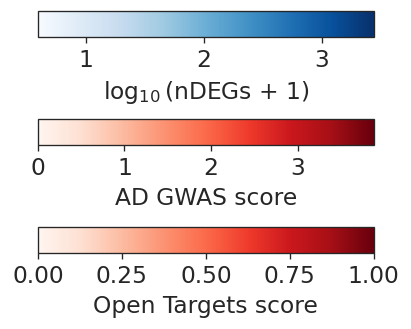

In [19]:
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# Exact mappings
disease_sm = ScalarMappable(
    norm=Normalize(0, 1),
    cmap=cmap
)

gwas_sm = ScalarMappable(
    norm=gwas_norm,
    cmap=cmap
)

deg_sm = ScalarMappable(
    norm=deg_norm,
    cmap=deg_cmap
)

fig = plt.figure(figsize=(4, 3))

# 1. DEGs
cax1 = fig.add_axes([0.15, 0.75, 0.7, 0.07])
cb1 = fig.colorbar(deg_sm, cax=cax1, orientation="horizontal")
cb1.set_label(r"$\log_{10}$(nDEGs + 1)")

# 2. AD GWAS
cax2 = fig.add_axes([0.15, 0.45, 0.7, 0.07])
cb2 = fig.colorbar(gwas_sm, cax=cax2, orientation="horizontal")
cb2.set_label("AD GWAS score")

# 3. Open Targets
cax3 = fig.add_axes([0.15, 0.15, 0.7, 0.07])
cb3 = fig.colorbar(disease_sm, cax=cax3, orientation="horizontal")
cb3.set_label("Open Targets score")

plt.savefig(
    "figures/heatmap_annotation_colorbars.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()

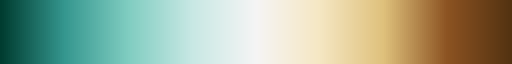

<Figure size 240x240 with 0 Axes>

In [20]:
from matplotlib.colors import LinearSegmentedColormap

palette = [
    "#533211",
    "#8c5322",
    "#dfc17c",
    "#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    #"#03675e",
    "#003c30"
]
palette= palette[::-1]

cmap = LinearSegmentedColormap.from_list("brown_teal", palette)
cmap
plt.savefig(
    "figures/heatmap_zscore_colorbar.pdf",
    bbox_inches="tight",
    transparent=True
)
cmap

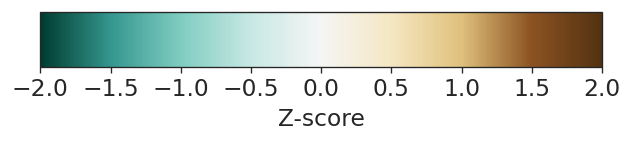

In [21]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

palette = [
    "#533211",
    "#8c5322",
    "#dfc17c",
    "#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    "#003c30"
][::-1]

cmap = LinearSegmentedColormap.from_list("brown_teal", palette)

fig, ax = plt.subplots(figsize=(6, 0.6))

norm = mpl.colors.Normalize(vmin=-2, vmax=2)

cb = mpl.colorbar.ColorbarBase(
    ax,
    cmap=cmap,
    norm=norm,
    orientation="horizontal"
)

cb.set_label("Z-score")

fig.savefig(
    "figures/heatmap_zscore_colorbar.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()

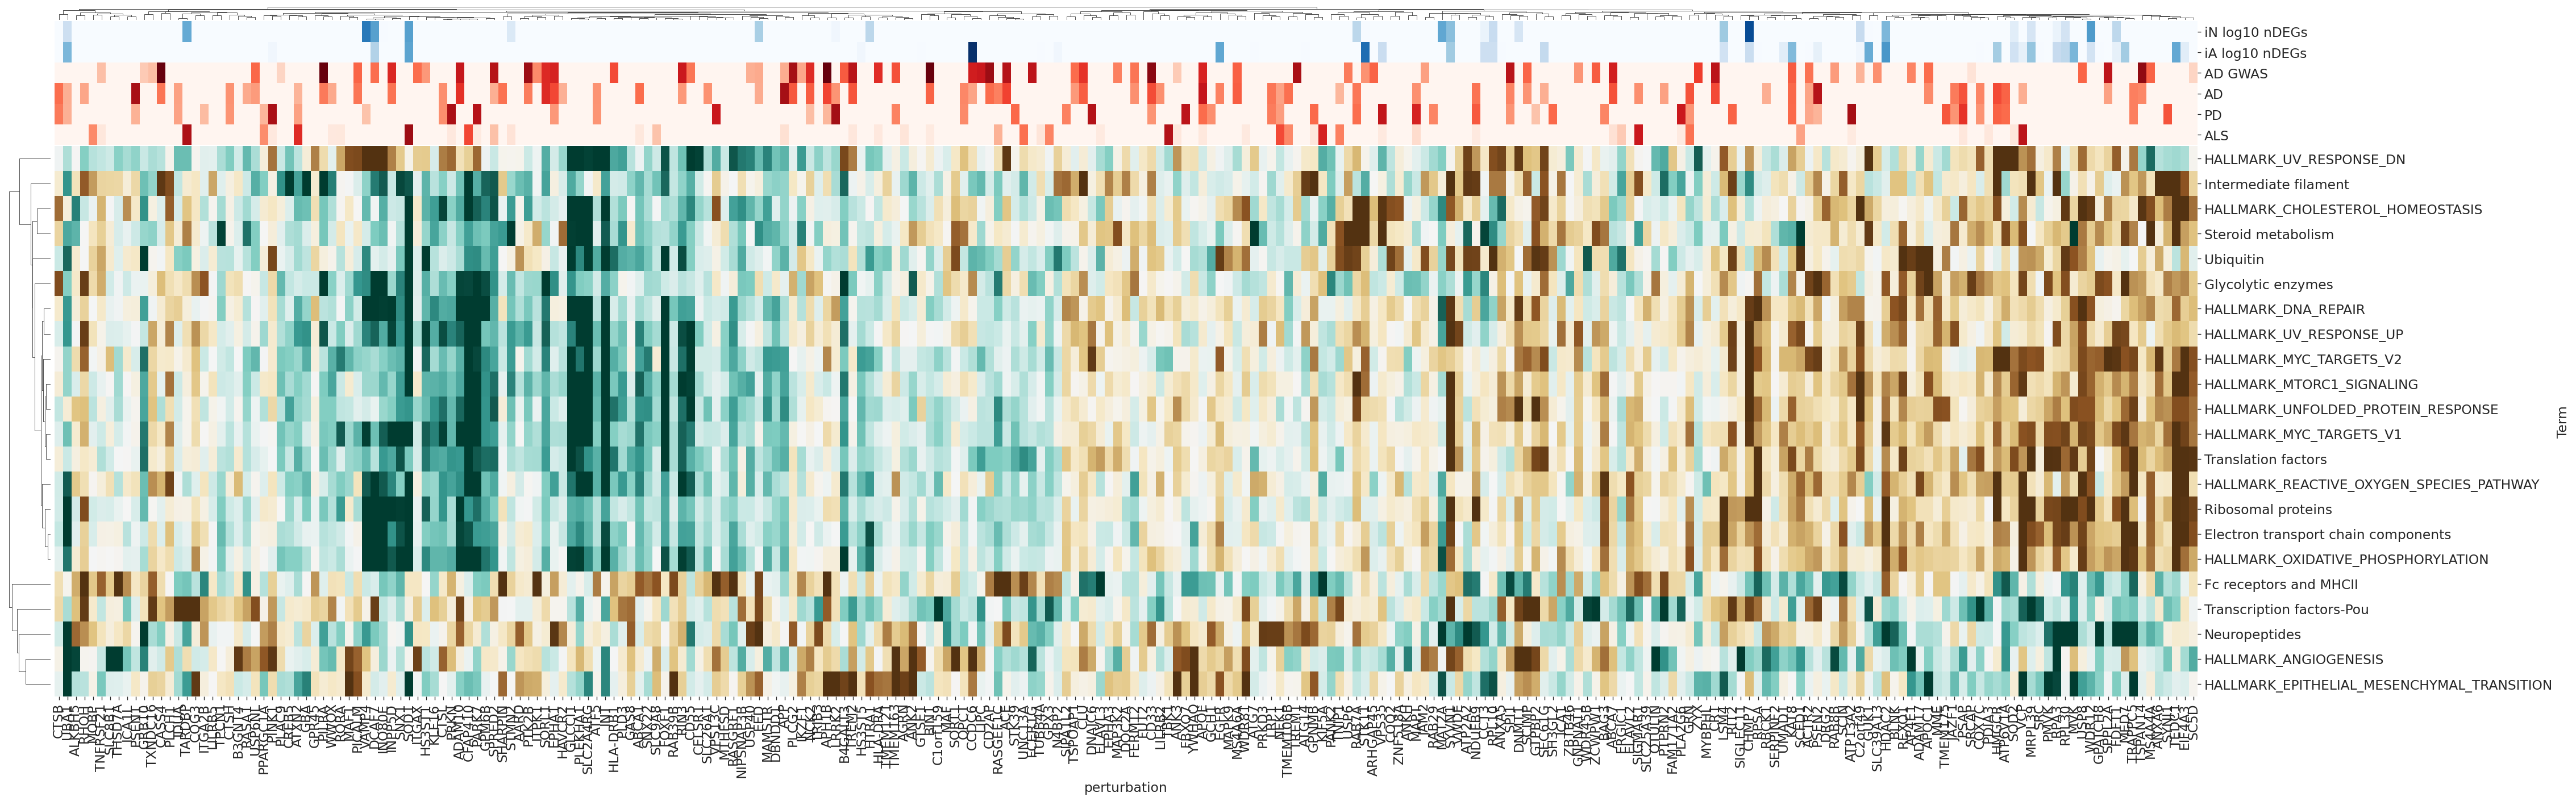

In [22]:
g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,
    row_cluster=True,
    col_cluster=True,
    col_colors=row_colors[['iN log10 nDEGs','iA log10 nDEGs','AD GWAS','AD', 'PD', 'ALS']],
    colors_ratio=0.03,
    figsize=(38, 12),
    xticklabels=True,
    yticklabels=True,
    dendrogram_ratio=(0.02, 0.02),  # hide dendrograms but keep clustering
    metric="correlation",
    method="average",
    cbar_pos=None
)

plt.savefig('figures/heatmap_GSVA_GSEAfilteredSignatures_iN2_v3.pdf')

# Get row/column order after clustering
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

# Reorder the original data
gsva_z_clustered = gsva_z.T.iloc[row_order, col_order]

# Save
gsva_z_clustered.to_csv("figures/heatmap_GSVA_GSEAfilteredSignatures_iN2_clustered_v3.csv")

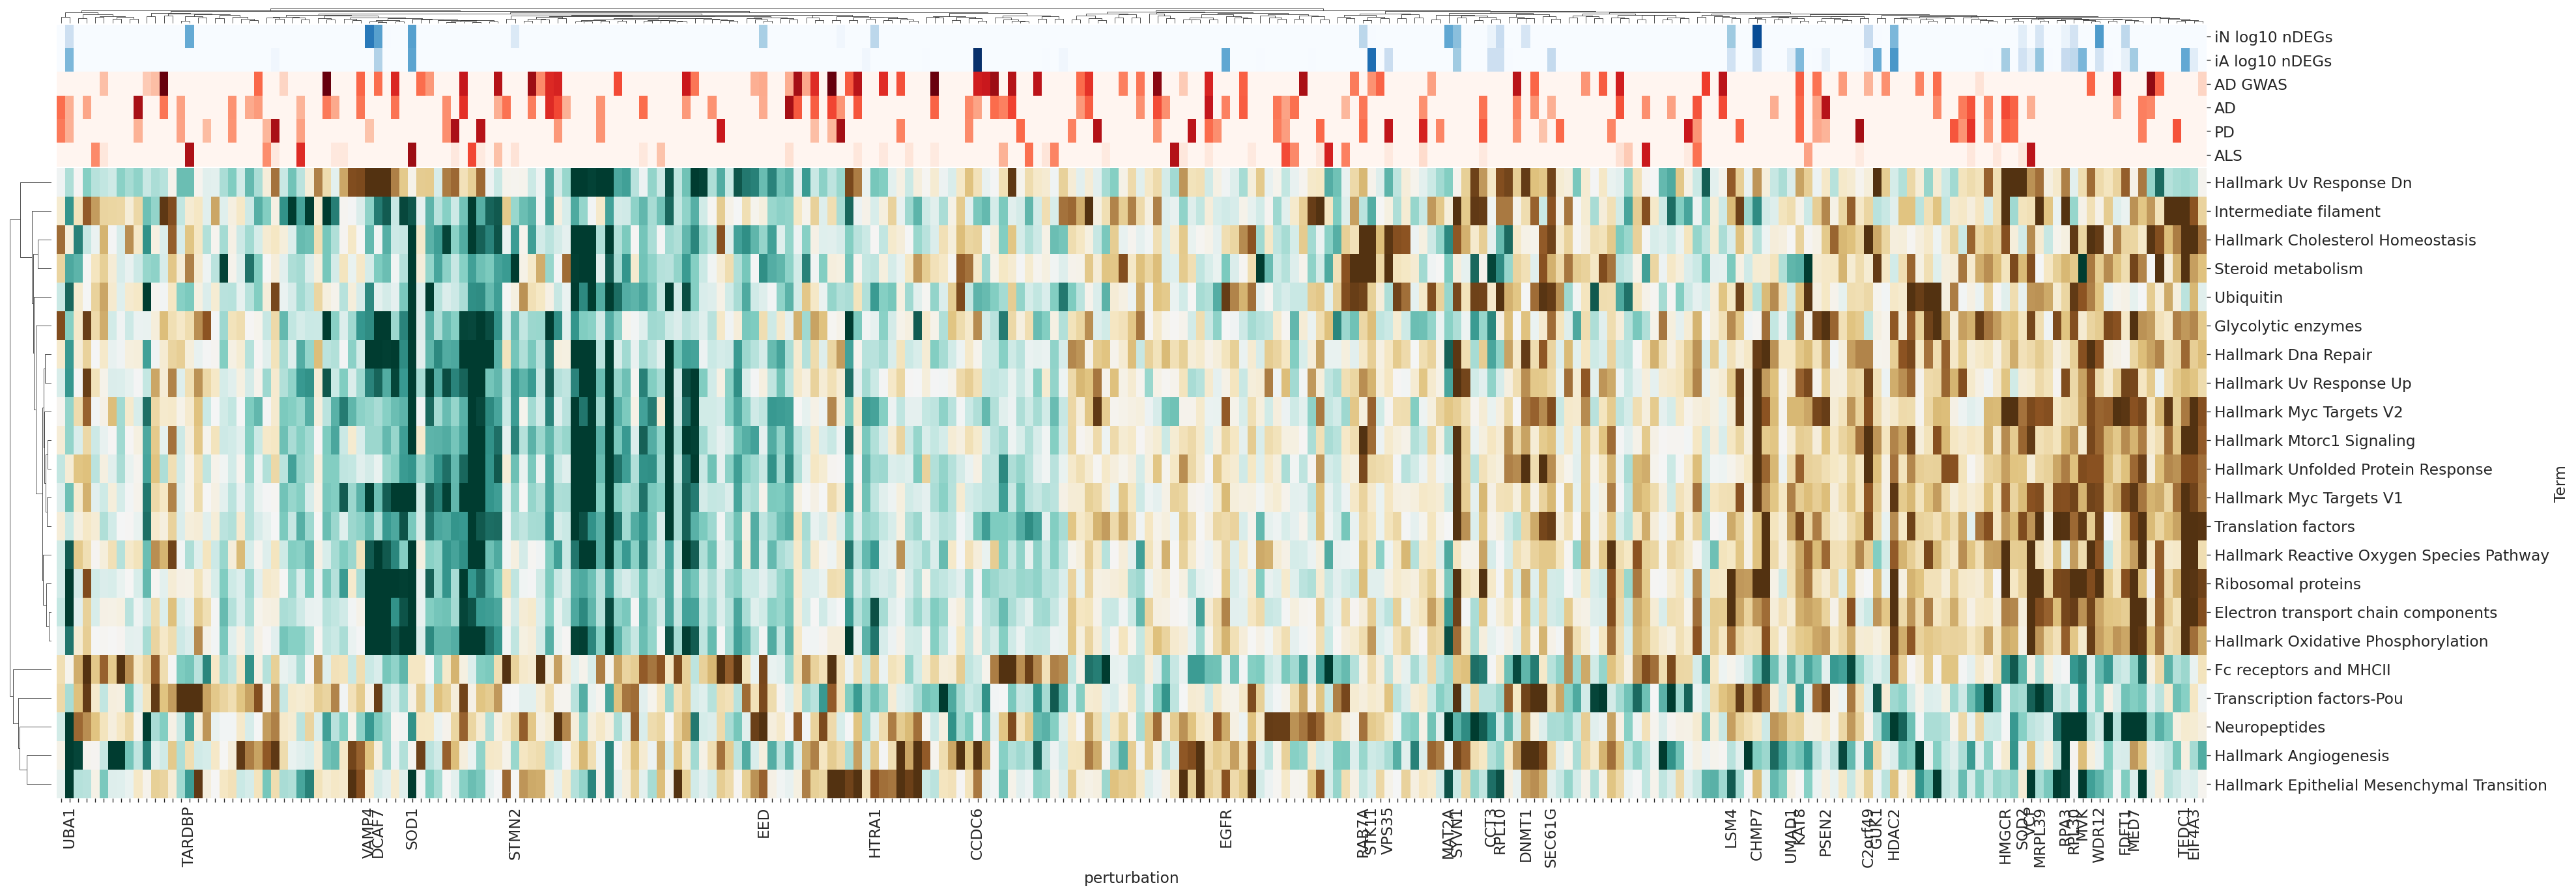

In [23]:
import re

# Genes to label = union of top iNeuron and iAstrocyte perturbations
label_genes = set(iN_top_genes) | set(iA_top_genes)


def clean_term(term):
    # Remove GO ID brackets, e.g.
    # "lysosome organization (GO:0007040)" -> "lysosome organization"
    term = re.sub(r"\s*\(GO:\d+\)\s*", "", term)

    # Clean Hallmark names
    if term.startswith("HALLMARK_"):
        term = term.replace("HALLMARK_", "Hallmark ").replace("_", " ").title()

    return term


g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,
    row_cluster=True,
    col_cluster=True,
    col_colors=row_colors[
        ['iN log10 nDEGs','iA log10 nDEGs', 'AD GWAS', 'AD', 'PD', 'ALS']
    ],
    colors_ratio=0.03,
    figsize=(34, 12),
    xticklabels=True,
    yticklabels=True,
    dendrogram_ratio=(0.02, 0.02),
    metric="correlation",
    method="average",
    cbar_pos=None
)

# Only label selected perturbation genes on columns
g.ax_heatmap.set_xticklabels([
    x.get_text() if x.get_text() in label_genes else ""
    for x in g.ax_heatmap.get_xticklabels()
], rotation=90)

# Clean ALL pathway/signature labels on rows
g.ax_heatmap.set_yticklabels([
    clean_term(x.get_text())
    for x in g.ax_heatmap.get_yticklabels()
])

plt.savefig(
    'figures/heatmap_GSVA_GSEAfilteredSignatures_iN2_v3_2.pdf',
    bbox_inches="tight"
)

In [ ]:
from scipy.cluster.hierarchy import fcluster

# linkage for perturbation genes
Z_genes = g.dendrogram_col.linkage

# cut dendrogram
t = 0.9  # adjust after looking at dendrogram

gene_clusters = pd.Series(
    fcluster(
        Z_genes,
        t=t,
        criterion="distance"
    ),
    index=gsva_z.T.columns,
    name="cluster"
)

gene_clusters.value_counts().sort_index()

cluster
1    10
2    14
3    94
4    31
5    11
6    16
7    75
Name: count, dtype: int64

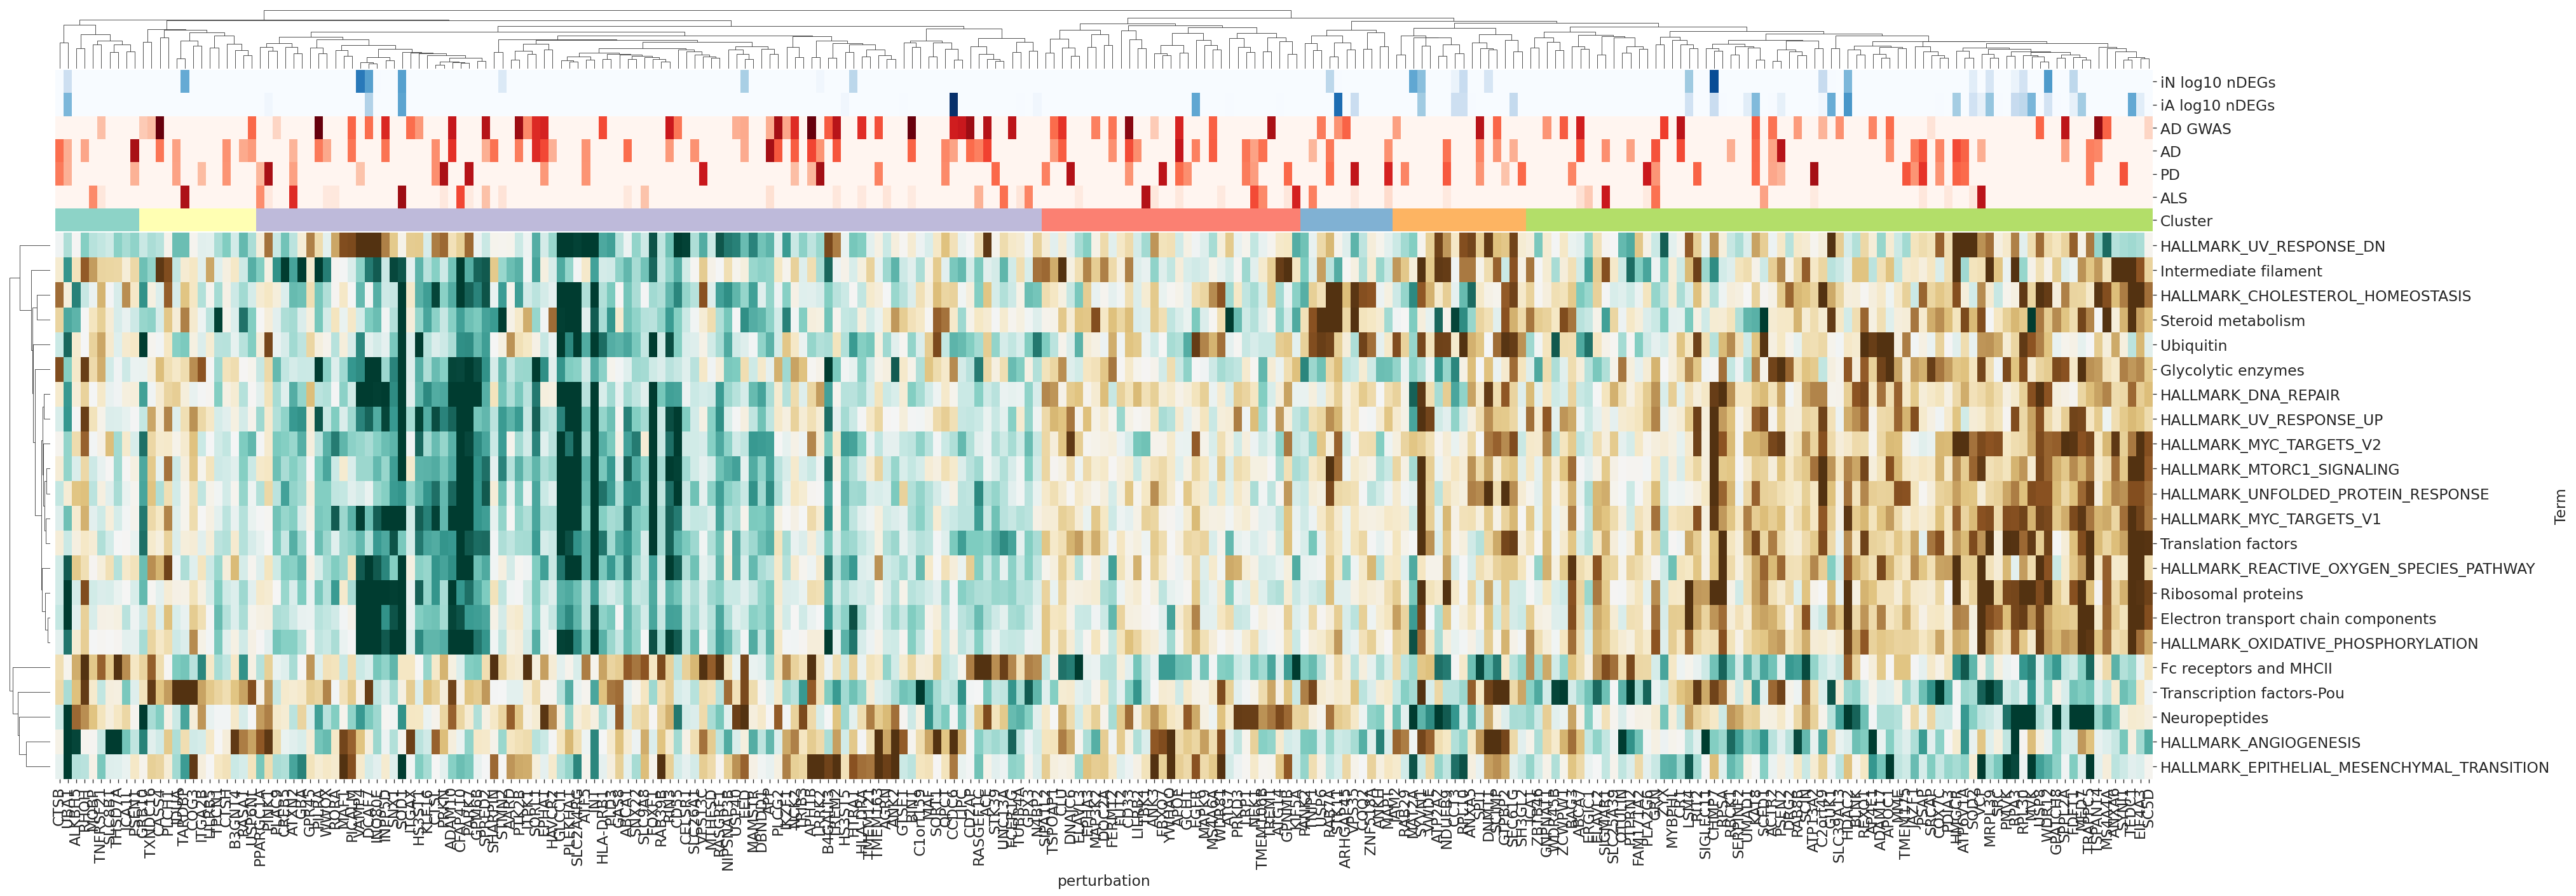

In [35]:
palette_clusters = [
    "#8dd3c7",
    "#ffffb3",
    "#bebada",
    "#fb8072",
    "#80b1d3",
    "#fdb462",
    "#b3de69",
]

uniq = sorted(gene_clusters.unique())
cluster_lut = dict(zip(uniq, palette_clusters))
cluster_colors = gene_clusters.map(cluster_lut)

annotation_colors = row_colors[
    ['iN log10 nDEGs', 'iA log10 nDEGs', 'AD GWAS', 'AD', 'PD', 'ALS']
].copy()

annotation_colors["Cluster"] = cluster_colors

g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,

    row_cluster=True,
    col_cluster=True,

    # critically, reuse the linkage we clustered/cut above
    col_linkage=Z_genes,

    col_colors=annotation_colors,
    colors_ratio=0.03,

    figsize=(34, 12),
    xticklabels=True,
    yticklabels=True,

    dendrogram_ratio=(0.02, 0.08),

    metric="correlation",
    method="average",
    cbar_pos=None
)

In [34]:
for cluster in sorted(gene_clusters.unique()):
    genes = gene_clusters[gene_clusters == cluster].index.tolist()
    print(f"\nCluster {cluster} (n={len(genes)}):")
    print(genes)

supp_table 


Cluster 1 (n=10):
['ALKBH5', 'CTSB', 'ICA1L', 'MOBP', 'PSEN1', 'RHOH', 'SLC8B1', 'THSD7A', 'TNFRSF21', 'UBA1']

Cluster 2 (n=14):
['B3GNT4', 'CASS4', 'COG3', 'CTSH', 'GRB10', 'IDUA', 'ITGA2B', 'LILRB5', 'PLCH1', 'RASA1', 'TARDBP', 'TPCN1', 'TXNDC16', 'USP6NL']

Cluster 3 (n=94):
['AARD', 'ABCA1', 'ACE', 'ADAM10', 'AGRN', 'ANK2', 'APH1B', 'APP', 'ATF5', 'ATXN2', 'B4GALT3', 'BIN1', 'C1orf159', 'CCDC6', 'CD2AP', 'CD55', 'CELSR1', 'CFAP410', 'CREB5', 'CTSL', 'DBNDD1', 'DCAF7', 'EED', 'EPHA1', 'FCER1G', 'FOXF1', 'GAS8', 'GBA', 'GLCCI1', 'GPM6B', 'GPR45', 'GPX3', 'GTSE1', 'HAVCR2', 'HLA-DRA', 'HLA-DRB1', 'HS3ST1', 'HS3ST5', 'HTRA1', 'IKZF1', 'INO80E', 'INPP5D', 'INT', 'ITGAX', 'ITPK1', 'KLF16', 'LIPC', 'LRRK2', 'MAF', 'MAF1', 'MAMSTR', 'MTHFSD', 'N4BP2', 'NCK2', 'NIPSNAP3B', 'PARK7', 'PICALM', 'PILRA', 'PINK1', 'PLAC9', 'PLCG2', 'PLD3', 'PLEKHA1', 'PPARGC1A', 'PRKN', 'PTK2B', 'QPCT', 'RAB39B', 'RASGEF1C', 'RASGRF1', 'RIN3', 'RORA', 'SHARPIN', 'SLC26A1', 'SLC2A4RG', 'SLC9A8', 'SNX1', 'SNX22'

,Gene,Cluster
8,ALKBH5,1
49,CTSB,1
97,ICA1L,1
126,MOBP,1
156,PSEN1,1
...,...,...
242,WDR12,7
243,WDR45B,7
247,ZBTB46,7
248,ZCWPW1,7


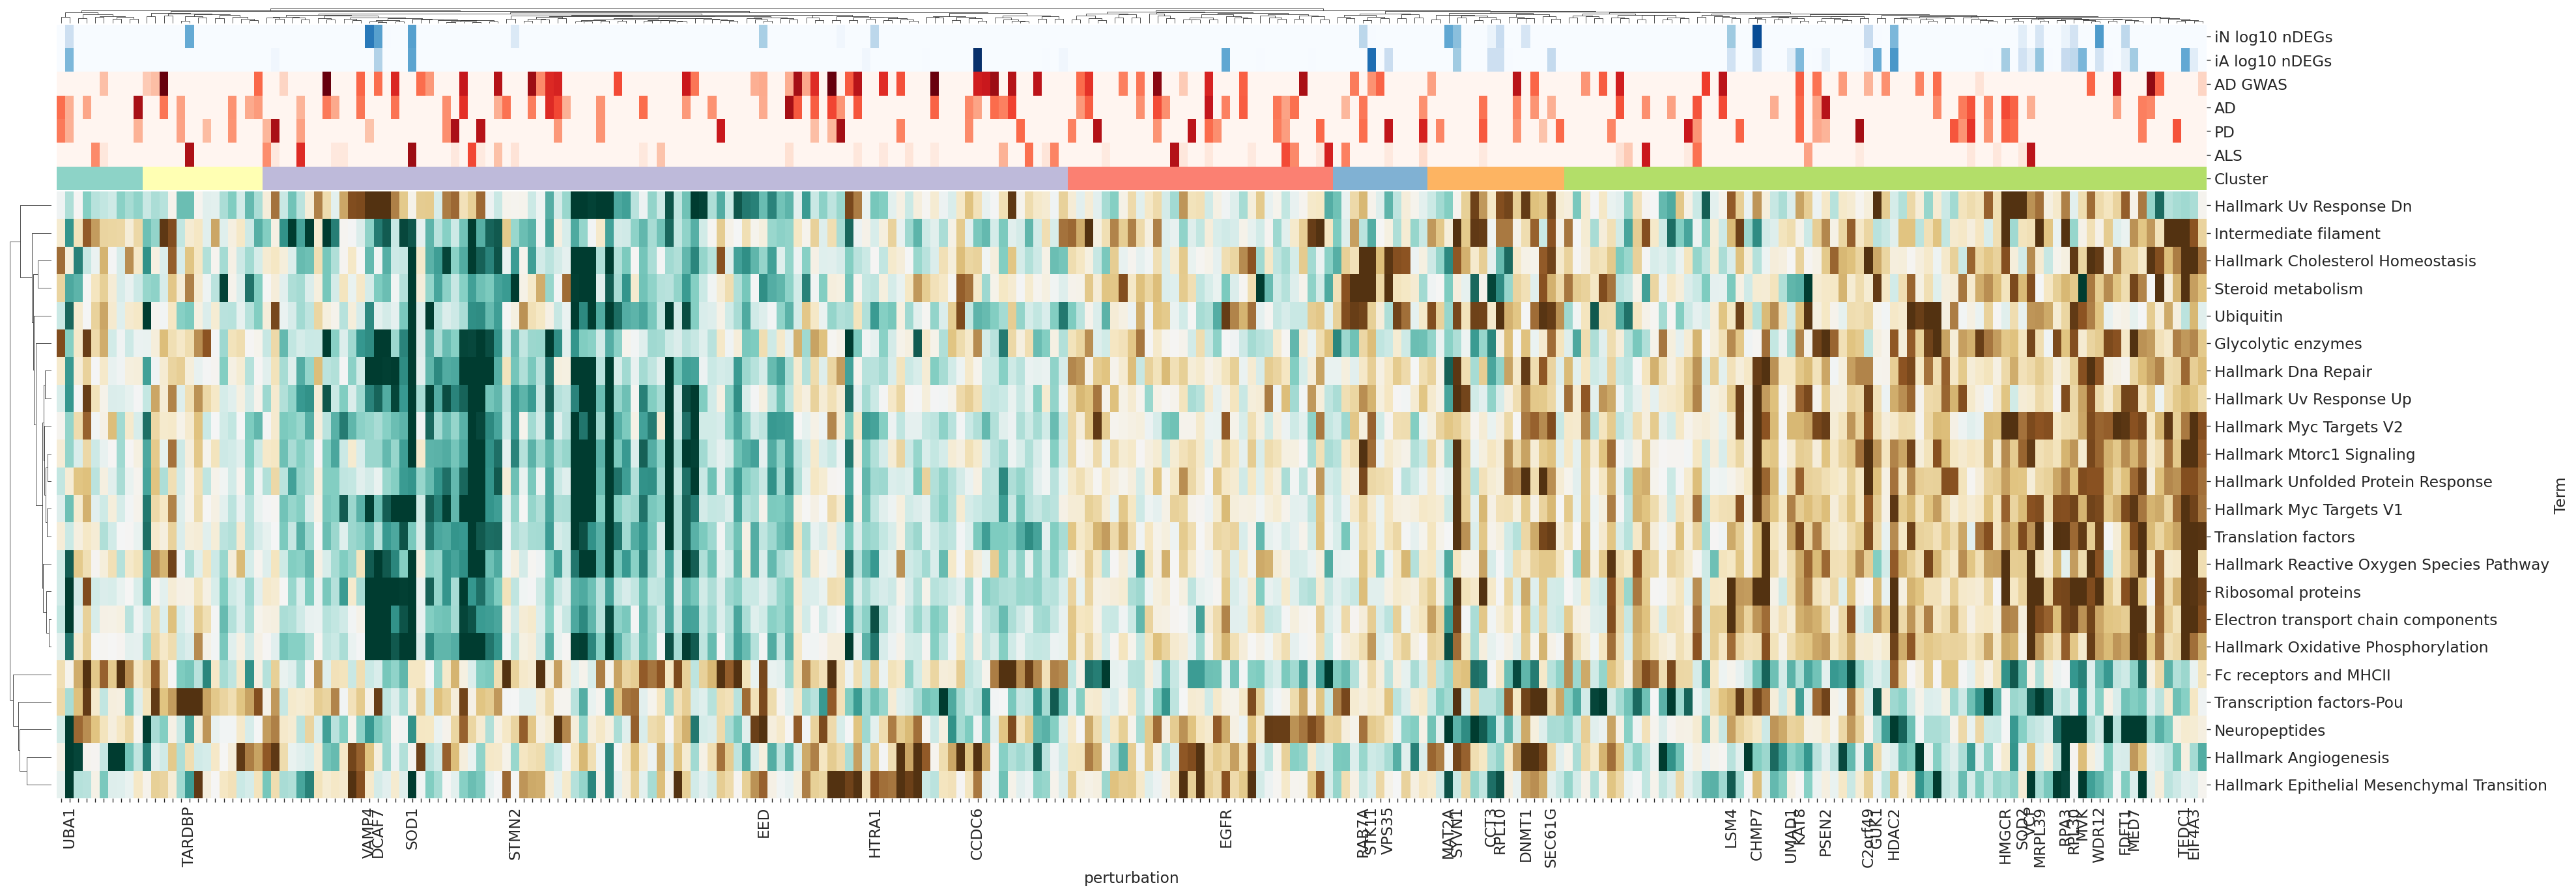

In [36]:
import re

# Genes to label = union of top iNeuron and iAstrocyte perturbations
label_genes = set(iN_top_genes) | set(iA_top_genes)


def clean_term(term):
    # Remove GO ID brackets
    term = re.sub(r"\s*\(GO:\d+\)\s*", "", term)

    # Clean Hallmark names
    if term.startswith("HALLMARK_"):
        term = term.replace("HALLMARK_", "Hallmark ").replace("_", " ").title()

    return term


# --------------------------------------------------
# Gene cluster annotation
# --------------------------------------------------

palette_clusters = [
    "#8dd3c7",
    "#ffffb3",
    "#bebada",
    "#fb8072",
    "#80b1d3",
    "#fdb462",
    "#b3de69",
]

uniq = sorted(gene_clusters.unique())
cluster_lut = dict(zip(uniq, palette_clusters))

cluster_colors = gene_clusters.map(cluster_lut)


# --------------------------------------------------
# Combine annotations
# --------------------------------------------------

annotation_colors = row_colors[
    [
        'iN log10 nDEGs',
        'iA log10 nDEGs',
        'AD GWAS',
        'AD',
        'PD',
        'ALS'
    ]
].copy()

annotation_colors["Cluster"] = cluster_colors


# --------------------------------------------------
# Heatmap
# --------------------------------------------------

g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,

    row_cluster=True,
    col_cluster=True,

    # Reuse the linkage used to define the clusters
    col_linkage=Z_genes,

    col_colors=annotation_colors,
    colors_ratio=0.03,

    figsize=(34, 12),
    xticklabels=True,
    yticklabels=True,

    dendrogram_ratio=(0.02, 0.02),

    metric="correlation",
    method="average",

    cbar_pos=None
)


# --------------------------------------------------
# Only label selected perturbation genes
# --------------------------------------------------

g.ax_heatmap.set_xticklabels([
    x.get_text() if x.get_text() in label_genes else ""
    for x in g.ax_heatmap.get_xticklabels()
], rotation=90)


# --------------------------------------------------
# Clean pathway/signature labels
# --------------------------------------------------

g.ax_heatmap.set_yticklabels([
    clean_term(x.get_text())
    for x in g.ax_heatmap.get_yticklabels()
])


# --------------------------------------------------
# Save
# --------------------------------------------------

plt.savefig(
    'figures/heatmap_GSVA_GSEAfilteredSignatures_iN2_v3_2_clustered.pdf',
    bbox_inches="tight"
)

In [38]:
supp_table = (
    gene_clusters
    .rename("Cluster")
    .rename_axis("Gene")
    .reset_index()
    .sort_values(["Cluster", "Gene"])
)

supp_table

,Gene,Cluster
8,ALKBH5,1
49,CTSB,1
97,ICA1L,1
126,MOBP,1
156,PSEN1,1
...,...,...
242,WDR12,7
243,WDR45B,7
247,ZBTB46,7
248,ZCWPW1,7


In [39]:
supp_table.to_csv('cluster_heatmap_iNeurons.csv')